# Motor Vehicle Theft Analysis
### Research question: Where were motor vehicle thefts concentrated across police districts, and how did each district's position change between 2017 and 2025?

## Hypothesis : I have to define

## 1. Imports

In [1]:
# Import required Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load dataset

In [2]:
df = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)
print("Original headers:", df.columns.tolist())

# If the first row was actually data (no header), reload with header=None
if str(df.columns[0]).strip().isdigit():
    df = pd.read_csv("dataset_coursework1-1.csv", header=None, low_memory=False)

Original headers: ['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']


In [3]:
# Assign standard 30-column NIBRS names by position
canonical_cols = [
    "Incident ID", "Offense Code", "CR Number", "Dispatch Date/Time",
    "Start Date/Time", "End Date/Time", "NIBRS Code", "Victims",
    "Crime Name 1", "Crime Name 2", "Crime Name 3", "Police District Name",
    "Block Address", "City", "State", "Zip Code", "Agency", "Place",
    "Sector", "Beat", "PRA", "Address Number", "Street Prefix",
    "Street Name", "Street Suffix", "Street Type", "Latitude",
    "Longitude", "Police District Number", "Geolocation"
]

if df.shape[1] == 30:
    df.columns = canonical_cols
else:
    raise ValueError(f"Expected 30 columns, found {df.shape[1]}. Check separator/encoding.")

total_raw_rows = len(df)
print(f"Total raw rows: {total_raw_rows:,} | Columns: {df.shape[1]}")

Total raw rows: 508,106 | Columns: 30


## 3. Data quality checks

In [4]:
# Ensure numeric types for Latitude/Longitude/Victims
for num_col in ["Latitude", "Longitude", "Victims"]:
    df[num_col] = pd.to_numeric(df[num_col], errors="coerce")

zero_coords = ((df["Latitude"] == 0.0) | (df["Longitude"] == 0.0)).sum()
null_coords = (df["Latitude"].isna() | df["Longitude"].isna()).sum()
print(f"Zeroed Coordinates (0.0): {zero_coords:,} ({zero_coords/total_raw_rows*100:.2f}%)")
print(f"Null Coordinates (NaN):   {null_coords:,} ({null_coords/total_raw_rows*100:.2f}%)")

# Date Parsing & Temporal Consistency Check
date_cols = ["Dispatch Date/Time", "Start Date/Time", "End Date/Time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

invalid_end = (df["End Date/Time"] < df["Start Date/Time"]).sum()
out_of_scope = ((df["Start Date/Time"] < "2016-07-01") | (df["Start Date/Time"] > "2026-09-10 23:59:59")).sum()
print(f"End Date < Start Date anomalies: {invalid_end:,} ({invalid_end/total_raw_rows*100:.2f}%)")
print(f"Out-of-scope timestamps:        {out_of_scope:,} ({out_of_scope/total_raw_rows*100:.2f}%)")

Zeroed Coordinates (0.0): 24,648 (4.85%)
Null Coordinates (NaN):   0 (0.00%)
End Date < Start Date anomalies: 8,418 (1.66%)
Out-of-scope timestamps:        228 (0.04%)


## 4. Cleaning, transformation & feature engineering

In [5]:
df_clean = df.copy()
df_clean.loc[(df_clean["Latitude"] == 0.0) | (df_clean["Longitude"] == 0.0), ["Latitude", "Longitude"]] = np.nan

df_clean["Crime Name 1"] = df_clean["Crime Name 1"].fillna("Unknown / Unclassified")
df_clean["Police District Name"] = df_clean["Police District Name"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")
df_clean["City"] = df_clean["City"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")

df_clean.loc[df_clean["End Date/Time"] < df_clean["Start Date/Time"], "End Date/Time"] = pd.NaT

exact_dups = df_clean.duplicated(subset=["Incident ID"], keep=False).sum()
print(f"Rows involved in duplicate Incident IDs: {exact_dups:,}")

df_clean = df_clean.drop_duplicates(subset=["Incident ID"])
print(f"Cleaned rows: {len(df_clean):,}")

# Feature Engineering
df_clean["Year"] = df_clean["Start Date/Time"].dt.year

Rows involved in duplicate Incident IDs: 74,254
Cleaned rows: 467,601


## 5. Motor vehicle theft subset

In [6]:
mvt = df_clean[(df_clean["Crime Name 2"] == "Motor Vehicle Theft") &
               (df_clean["Start Date/Time"] >= "2016-07-01") &
               (df_clean["Start Date/Time"] <= "2026-09-10 23:59:59")].copy()

print(f"Motor vehicle thefts: {len(mvt):,}")

Motor vehicle thefts: 16,750


## 6. Concentration of thefts

In [7]:
def concentration(col, top=15):
    t = mvt[col].value_counts().rename("Count").to_frame()
    t["Percent"] = (t["Count"] / t["Count"].sum() * 100).round(2)
    t["Cumulative_%"] = t["Percent"].cumsum().round(2)
    return t.head(top)

display(concentration("Police District Name"))
display(concentration("City"))
display(concentration("Beat"))
display(concentration("Place"))

,Count,Percent,Cumulative_%
Police District Name,,,
SILVER SPRING,5184,31.09,31.09
WHEATON,3071,18.42,49.51
MONTGOMERY VILLAGE,2749,16.48,65.99
BETHESDA,2001,12.00,77.99
ROCKVILLE,1634,9.80,87.79
GERMANTOWN,1535,9.20,96.99
TAKOMA PARK,500,3.00,99.99
OTHER,2,0.01,100.00


,Count,Percent,Cumulative_%
City,,,
SILVER SPRING,7439,44.41,44.41
GAITHERSBURG,2085,12.45,56.86
ROCKVILLE,2036,12.16,69.02
GERMANTOWN,1232,7.36,76.38
BETHESDA,831,4.96,81.34
TAKOMA PARK,627,3.74,85.08
MONTGOMERY VILLAGE,626,3.74,88.82
BURTONSVILLE,382,2.28,91.10
CHEVY CHASE,297,1.77,92.87


,Count,Percent,Cumulative_%
Beat,,,
3G1,1321,7.89,7.89
3I2,1226,7.32,15.21
3I1,1159,6.92,22.13
4K1,781,4.66,26.79
4L1,648,3.87,30.66
6P1,529,3.16,33.82
6R2,513,3.06,36.88
5N1,510,3.04,39.92
4L2,504,3.01,42.93


,Count,Percent,Cumulative_%
Place,,,
Parking Lot - Residential,5462,32.61,32.61
Street - Residential,3890,23.22,55.83
Residence - Driveway,1599,9.55,65.38
Parking Lot - Commercial,1102,6.58,71.96
Parking Garage - Residential,646,3.86,75.82
Street - Commercial,455,2.72,78.54
Auto Dealership,381,2.27,80.81
Residence - Single Family,357,2.13,82.94
Street - Other,308,1.84,84.78


In [8]:
geo = mvt.dropna(subset=["Latitude", "Longitude"]).copy()
geo["Lat_Grid"] = geo["Latitude"].round(2)
geo["Lon_Grid"] = geo["Longitude"].round(2)

hotspots = (
    geo.groupby(["Lat_Grid", "Lon_Grid"])
    .agg(Count=("Incident ID", "count"),
         Main_City=("City", lambda s: s.mode().iat[0]),
         Main_District=("Police District Name", lambda s: s.mode().iat[0]))
    .sort_values("Count", ascending=False)
    .reset_index()
)
hotspots["Percent"] = (hotspots["Count"] / len(geo) * 100).round(2)
display(hotspots.head(20))

,Lat_Grid,Lon_Grid,Count,Main_City,Main_District,Percent
0,38.99,-77.03,377,SILVER SPRING,SILVER SPRING,2.48
1,39.08,-76.94,310,SILVER SPRING,SILVER SPRING,2.04
2,39.04,-76.99,308,SILVER SPRING,SILVER SPRING,2.03
3,39.00,-77.03,254,SILVER SPRING,SILVER SPRING,1.67
4,38.99,-77.02,234,SILVER SPRING,SILVER SPRING,1.54
5,39.04,-77.05,215,SILVER SPRING,WHEATON,1.42
6,39.09,-77.07,175,SILVER SPRING,WHEATON,1.15
7,39.00,-77.00,175,SILVER SPRING,SILVER SPRING,1.15
8,39.05,-76.98,168,SILVER SPRING,SILVER SPRING,1.11
9,39.06,-77.05,160,SILVER SPRING,WHEATON,1.05


## 7. Thefts by district and year (complete years 2017–2025)

In [9]:
# Motor vehicle thefts only, full calendar years (drops partial 2016 and 2026)
mvt_full = mvt[mvt["Year"].between(2017, 2025)]

district_year = pd.crosstab(mvt_full["Police District Name"], mvt_full["Year"],
                            margins=True, margins_name="Total")
display(district_year)

# Each district's share of the county total per year (%)
district_share = pd.crosstab(mvt_full["Police District Name"], mvt_full["Year"],
                             normalize="columns").mul(100).round(1)
display(district_share)

# District rank per year (1 = most thefts)
district_rank = pd.crosstab(mvt_full["Police District Name"], mvt_full["Year"]) \
                  .rank(ascending=False, method="min").astype(int)
display(district_rank)

Year,2017,2018,2019,2020,2021,2022,2023,2024,2025,Total
Police District Name,,,,,,,,,,
BETHESDA,94,97,104,149,230,242,311,245,280,1752
GERMANTOWN,82,61,65,113,127,99,290,241,197,1275
MONTGOMERY VILLAGE,135,138,144,181,193,197,520,454,298,2260
OTHER,0,0,1,0,0,0,1,0,0,2
ROCKVILLE,85,69,91,96,147,159,242,318,198,1405
SILVER SPRING,269,255,271,338,407,372,1102,827,711,4552
TAKOMA PARK,32,30,22,39,35,47,100,71,73,449
WHEATON,161,114,142,147,194,263,598,575,446,2640
Total,858,764,840,1063,1333,1379,3164,2731,2203,14335


Year,2017,2018,2019,2020,2021,2022,2023,2024,2025
Police District Name,,,,,,,,,
BETHESDA,11.0,12.7,12.4,14.0,17.3,17.5,9.8,9.0,12.7
GERMANTOWN,9.6,8.0,7.7,10.6,9.5,7.2,9.2,8.8,8.9
MONTGOMERY VILLAGE,15.7,18.1,17.1,17.0,14.5,14.3,16.4,16.6,13.5
OTHER,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0
ROCKVILLE,9.9,9.0,10.8,9.0,11.0,11.5,7.6,11.6,9.0
SILVER SPRING,31.4,33.4,32.3,31.8,30.5,27.0,34.8,30.3,32.3
TAKOMA PARK,3.7,3.9,2.6,3.7,2.6,3.4,3.2,2.6,3.3
WHEATON,18.8,14.9,16.9,13.8,14.6,19.1,18.9,21.1,20.2


Year,2017,2018,2019,2020,2021,2022,2023,2024,2025
Police District Name,,,,,,,,,
BETHESDA,4,4,4,3,2,3,4,5,4
GERMANTOWN,6,6,6,5,6,6,5,6,6
MONTGOMERY VILLAGE,3,2,2,2,4,4,3,3,3
OTHER,8,8,8,8,8,8,8,8,8
ROCKVILLE,5,5,5,6,5,5,6,4,5
SILVER SPRING,1,1,1,1,1,1,1,1,1
TAKOMA PARK,7,7,7,7,7,7,7,7,7
WHEATON,2,3,3,4,3,2,2,2,2


## 8. Figure 1. Total recorded motor vehicle thefts by police district, 2017–2025

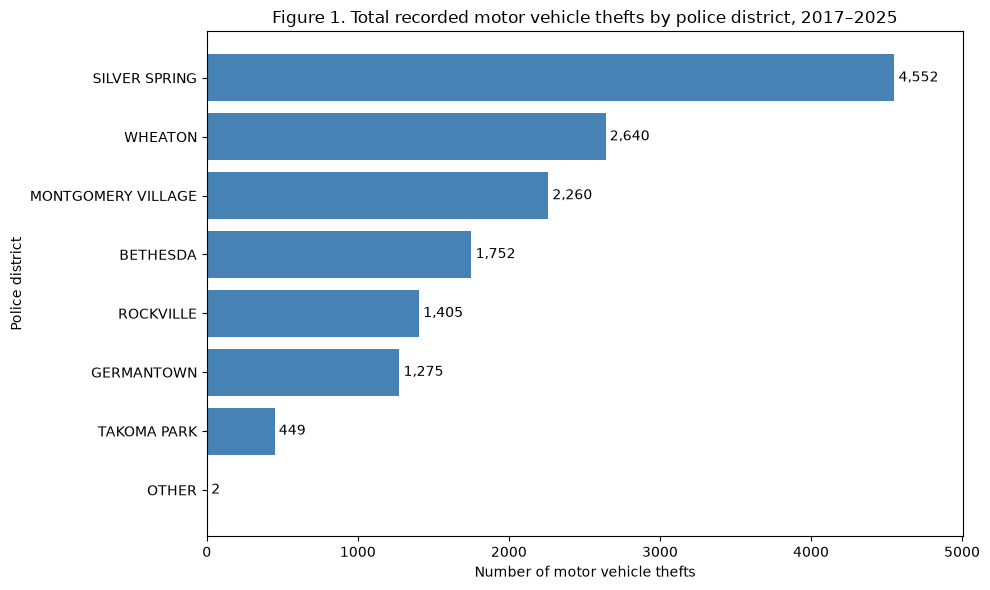

Silver Spring: 4,552 thefts (31.8% of county total)
Wheaton: 2,640 thefts (18.4% of county total)
Combined: 7,192 of 14,335 thefts = 50.2% of the county total


In [10]:
district_totals = mvt_full["Police District Name"].value_counts()
county_total = district_totals.sum()

fig, ax = plt.subplots(figsize=(10, 6))
plot_data = district_totals.sort_values(ascending=True)
bars = ax.barh(plot_data.index, plot_data.values, color="steelblue")
ax.bar_label(bars, labels=[f"{v:,}" for v in plot_data.values], padding=3)

ax.set_title("Figure 1. Total recorded motor vehicle thefts by police district, 2017–2025")
ax.set_xlabel("Number of motor vehicle thefts")
ax.set_ylabel("Police district")
ax.margins(x=0.1)
plt.tight_layout()
plt.show()

top2 = district_totals.head(2)
top2_share = top2.sum() / county_total * 100

for district, count in top2.items():
    print(f"{district.title()}: {count:,} thefts ({count / county_total * 100:.1f}% of county total)")
print(f"Combined: {top2.sum():,} of {county_total:,} thefts = {top2_share:.1f}% of the county total")

## 9. Figure 2. District rank by year, 2017–2025

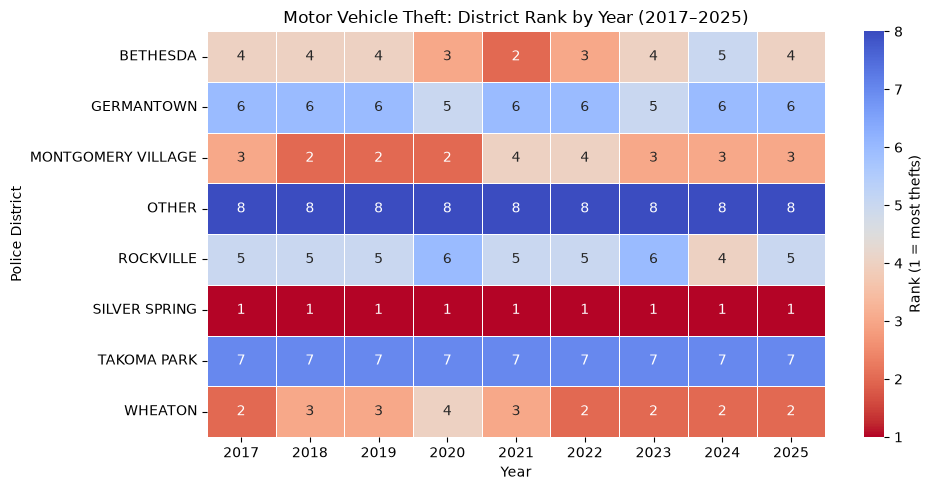

In [11]:
plt.figure(figsize=(10, 5))
sns.heatmap(district_rank, annot=True, fmt="d", cmap="coolwarm_r",
            linewidths=0.5, cbar_kws={"label": "Rank (1 = most thefts)"})
plt.title("Motor Vehicle Theft: District Rank by Year (2017–2025)")
plt.xlabel("Year")
plt.ylabel("Police District")
plt.tight_layout()
plt.show()